In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/reviews.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (7000, 2)

Column names:
['review', 'category']


,review,category
0,The product's innovative features have greatly...,Product Feedback
1,Customer service was unresponsive to my inquir...,Customer Service
2,"I was a victim of fraud, the seller requested ...",Fraud and Scam
3,The delivery was delayed due to unforeseen cir...,Operational Issues
4,"The product arrived with some defects, but the...",Product Feedback


In [18]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSample records:")
display(df.sample(min(5, len(df)), random_state=42))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   review    7000 non-null   object
 1   category  7000 non-null   object
dtypes: object(2)
memory usage: 109.5+ KB

Missing values:
review      0
category    0
dtype: int64

Sample records:


,review,category
6500,"The packaging was damaged upon arrival, and so...",Operational Issues
2944,"There were glitches on the website, making it ...",Operational Issues
2024,I had a great experience with the support team...,Customer Service
263,The support team was knowledgeable and provide...,Customer Service
4350,"Unfortunately, the product did not meet my exp...",Product Feedback


In [19]:
df = df.dropna(subset=["review"]).copy()

df["review"] = df["review"].astype(str).str.strip()

df = df[df["review"].str.len() > 10]

df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

print("Reviews after cleaning:", len(df))
display(df[["review"]].head())

Reviews after cleaning: 320


,review
0,The product's innovative features have greatly...
1,Customer service was unresponsive to my inquir...
2,"I was a victim of fraud, the seller requested ..."
3,The delivery was delayed due to unforeseen cir...
4,"The product arrived with some defects, but the..."


In [20]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")

texts = df["review"].tolist()

embeddings = model.encode(
    texts,
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Number of reviews:", len(texts))
print("Embedding matrix shape:", embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

Number of reviews: 320
Embedding matrix shape: (320, 384)


In [21]:
from sklearn.cluster import KMeans

n_clusters = 5

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(embeddings)
print("Cluster distribution:")
print(df["cluster"].value_counts().sort_index())

Cluster distribution:
cluster
0     23
1    117
2     39
3     77
4     64
Name: count, dtype: int64


In [22]:
for cluster_id in sorted(df["cluster"].unique()):
    print(f"\n{'=' * 20} CLUSTER {cluster_id} {'=' * 20}")

    samples = df.loc[
        df["cluster"] == cluster_id, "review"
    ].head(5)

    for review in samples:
        print("-", review)


==================== CLUSTER 0 ====================
- The delivery was delayed due to unforeseen circumstances, but I was informed promptly.
- The delivery was delayed due to unforeseen circumstances, but the seller was transparent about the situation.
- The delivery was on time and the packaging was in excellent condition.
- The delivery was delayed due to unforeseen circumstances, but the seller provided regular updates and a compensation.
- The delivery was delayed by two weeks, which was very inconvenient.

==================== CLUSTER 1 ====================
- The product's innovative features have greatly improved my daily tasks.
- The product features are impressive and have greatly improved my daily tasks.
- The features of this product are innovative and very useful for my daily needs.
- The product features are impressive and I'm satisfied with my purchase.
- The product is a game-changer, the features are incredibly useful.

==================== CLUSTER 2 ===================

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2
)

tfidf_matrix = vectorizer.fit_transform(df["review"])
terms = np.array(vectorizer.get_feature_names_out())

for cluster_id in sorted(df["cluster"].unique()):

    # Convert the Pandas Series to a NumPy Boolean array
    cluster_mask = (df["cluster"] == cluster_id).to_numpy()

    # Calculate average TF-IDF scores for this cluster
    mean_scores = np.asarray(
        tfidf_matrix[cluster_mask].mean(axis=0)
    ).ravel()

    top_indices = mean_scores.argsort()[-10:][::-1]
    keywords = terms[top_indices]

    print(f"\nCluster {cluster_id}")
    print("Top keywords:", ", ".join(keywords))

    samples = df.loc[
        df["cluster"] == cluster_id, "review"
    ].head(3)

    print("Sample reviews:")
    for review in samples:
        print("-", review)


Cluster 0
Top keywords: delivery, delayed, delivery delayed, delivery time, time, condition, time product, packaging, process, delayed week
Sample reviews:
- The delivery was delayed due to unforeseen circumstances, but I was informed promptly.
- The delivery was delayed due to unforeseen circumstances, but the seller was transparent about the situation.
- The delivery was on time and the packaging was in excellent condition.

Cluster 1
Top keywords: product design, design, product, features, product features, love, innovative, sleek, minimalist, modern
Sample reviews:
- The product's innovative features have greatly improved my daily tasks.
- The product features are impressive and have greatly improved my daily tasks.
- The features of this product are innovative and very useful for my daily needs.

Cluster 2
Top keywords: received, fraudulent, scammed, seller, activity, fraudulent activity, scammed received, received product, scam, order
Sample reviews:
- I was a victim of fraud, t

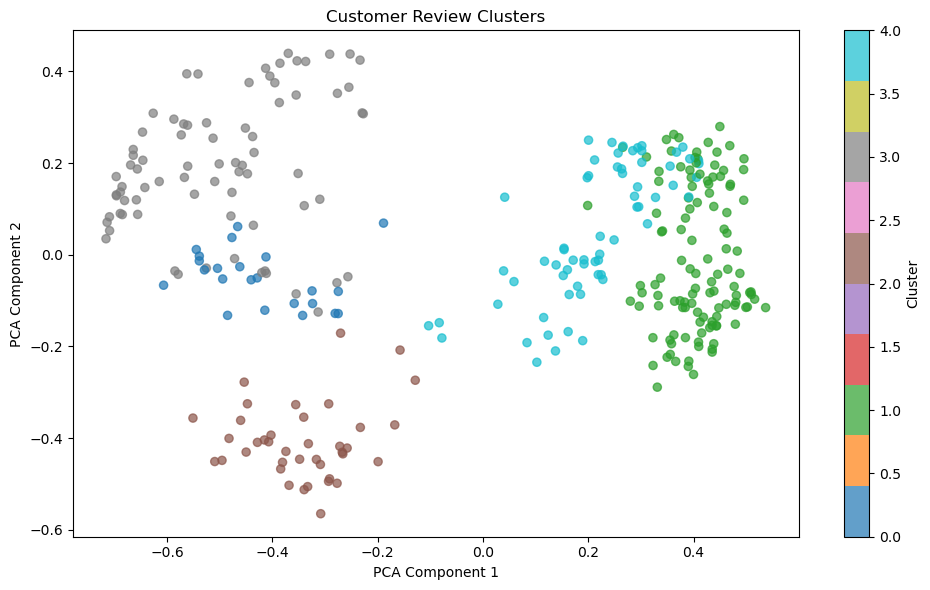

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
coordinates = pca.fit_transform(embeddings)

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    coordinates[:, 0],
    coordinates[:, 1],
    c=df["cluster"],
    cmap="tab10",
    alpha=0.7,
    s=35
)

plt.title("Customer Review Clusters")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

## 2. Topic Modeling with BERTopic

In this section, we use BERTopic to discover semantic topics
in customer reviews.

The pipeline consists of:
1. Sentence embeddings using SBERT
2. Dimensionality reduction using UMAP
3. Density-based clustering using HDBSCAN
4. Word counting using CountVectorizer
5. Topic representation using c-TF-IDF

In [23]:
import bertopic
import umap
import hdbscan

print("BERTopic version:", bertopic.__version__)
print("All required modules imported successfully!")

BERTopic version: 0.17.4
All required modules imported successfully!


In [24]:
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer

# Prepare the text documents
docs = df["review"].astype(str).tolist()

# Stage 1: Sentence embeddings
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Stage 2: Dimensionality reduction
umap_model = UMAP(
    n_neighbors=10,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=42
)

# Stage 3: Density-based clustering
hdbscan_model = HDBSCAN(
    min_cluster_size=10,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True
)

# Stage 4: Tokenization and word counting
vectorizer_model = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2
)

# Stage 5: Class-based TF-IDF
ctfidf_model = ClassTfidfTransformer()

# Assemble the complete pipeline
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    verbose=True
)

print("BERTopic pipeline configured successfully!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BERTopic pipeline configured successfully!


In [25]:
topics, probabilities = topic_model.fit_transform(docs)

df["topic"] = topics

print("Topic modeling completed!")
print("Number of topics:", len(set(topics) - {-1}))
print("Outlier reviews:", sum(t == -1 for t in topics))

2026-10-17 10:33:53,277 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

2026-10-17 10:33:55,294 - BERTopic - Embedding - Completed ✓
2026-10-17 10:33:55,295 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-17 10:33:56,034 - BERTopic - Dimensionality - Completed ✓
2026-10-17 10:33:56,035 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-17 10:33:56,051 - BERTopic - Cluster - Completed ✓
2026-10-17 10:33:56,056 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-17 10:33:56,081 - BERTopic - Representation - Completed ✓


Topic modeling completed!
Number of topics: 8
Outlier reviews: 8


In [13]:
topic_info = topic_model.get_topic_info()
display(topic_info.head(20))

,Topic,Count,Name,Representation,Representative_Docs
0,-1,8,-1_website_issues_placing order_placing,"[website, issues, placing order, placing, orde...",[I faced several issues while placing my order...
1,0,66,0_issue_provided_helpful_resolved,"[issue, provided, helpful, resolved, team, qui...",[The customer service team was friendly and he...
2,1,57,1_product design_design_love product_love,"[product design, design, love product, love, p...","[The product's design is vintage and retro., T..."
3,2,43,2_seller_received_did_seller provided,"[seller, received, did, seller provided, meet,...","[I was a victim of fraud, the seller provided ..."
4,3,41,3_features_product features_innovative_useful,"[features, product features, innovative, usefu...",[The product's features are versatile and adap...
5,4,32,4_expectations_expectations product_quality_ex...,"[expectations, expectations product, quality, ...",[The product quality is excellent. It works ex...
6,5,29,5_product performance_performance_efficient_re...,"[product performance, performance, efficient, ...",[The product's performance is fast and powerfu...
7,6,25,6_time_process_operational issues_time product,"[time, process, operational issues, time produ...",[The delivery process had some operational iss...
8,7,19,7_product design_design_elegant_product,"[product design, design, elegant, product, fun...",[The product's design is minimalist and unclut...


## 3. Topic Visualization and Interpretation

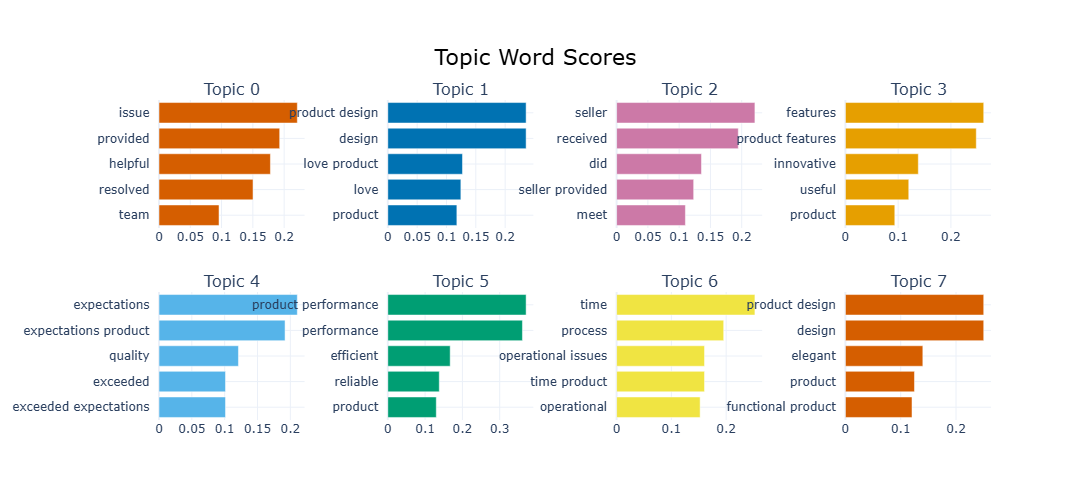

In [14]:
topic_model.visualize_barchart(top_n_topics=10)

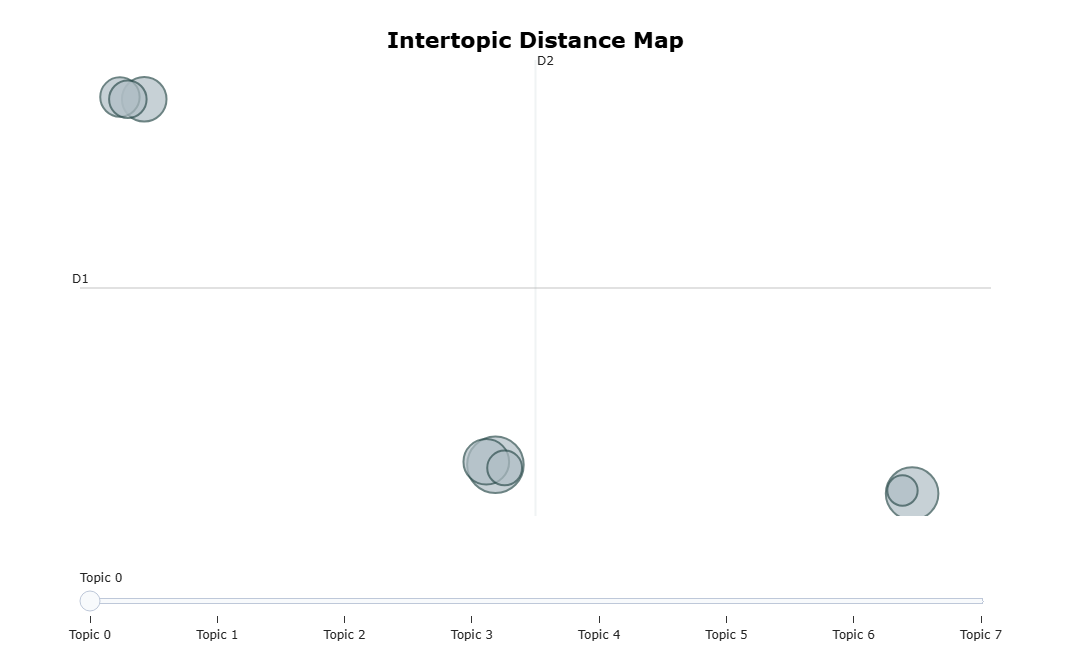

In [26]:
topic_model.visualize_topics()

In [16]:
for topic_id in sorted(df["topic"].unique()):
    print(f"\n{'=' * 50}")
    print(f"TOPIC {topic_id}")
    print("=" * 50)

    topic_reviews = df.loc[
        df["topic"] == topic_id, "review"
    ].head(5)

    for review in topic_reviews:
        print("-", review)


TOPIC -1
- I faced several issues while placing my order on the website, but the support team was helpful and resolved them.
- The website had some technical issues, but the support team was quick to resolve them.
- There were glitches on the website, making it difficult to complete my purchase.
- I faced several issues while placing my order on the website, it kept crashing.
- I faced several issues while placing my order, the website was unresponsive.

TOPIC 0
- Customer service was unresponsive to my inquiry. I'm disappointed with the experience.
- Customer service was incredibly helpful and resolved my issue within minutes.
- Customer service was knowledgeable and provided excellent assistance throughout the purchasing process.
- Customer service was not helpful and did not provide a satisfactory solution to my issue.
- Customer service was incredibly helpful and resolved my issue promptly.

TOPIC 1
- The product's design is sleek and user-friendly.
- The product's design is visua

In [17]:
topic_labels = {
    -1: "Unassigned Reviews",
     0: "Customer Service",
     1: "Product Design",
     2: "Seller Experience",
     3: "Product Features",
     4: "Product Quality",
     5: "Product Performance",
     6: "Delivery and Operations",
     7: "Design and Aesthetics"
}

topic_model.set_topic_labels(topic_labels)

df["topic_name"] = df["topic"].map(topic_labels)

display(
    df[["review", "cluster", "topic", "topic_name"]].head(10)
)

,review,cluster,topic,topic_name
0,The product's innovative features have greatly...,1,3,Product Features
1,Customer service was unresponsive to my inquir...,3,0,Customer Service
2,"I was a victim of fraud, the seller requested ...",2,2,Seller Experience
3,The delivery was delayed due to unforeseen cir...,0,6,Delivery and Operations
4,"The product arrived with some defects, but the...",2,2,Seller Experience
5,Customer service was incredibly helpful and re...,3,0,Customer Service
6,"I was scammed by a fraudulent seller, they too...",2,2,Seller Experience
7,I faced several issues while placing my order ...,3,-1,Unassigned Reviews
8,The product exceeded my expectations in terms ...,4,4,Product Quality
9,I encountered a minor operational issue with t...,3,2,Seller Experience


In [27]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

df.to_csv(
    output_dir / "reviews_with_topics.csv",
    index=False
)

topic_info.to_csv(
    output_dir / "topic_summary.csv",
    index=False
)

print("Topic results saved successfully!")

Topic results saved successfully!


In [28]:
comparison = pd.DataFrame({
    "KMeans": df["cluster"].value_counts(),
    "BERTopic": df["topic"].value_counts()
}).fillna(0).astype(int)

print(comparison)

    KMeans  BERTopic
-1       0         8
 0      23        66
 1     117        57
 2      39        43
 3      77        41
 4      64        32
 5       0        29
 6       0        25
 7       0        19


## 4. Model Evaluation

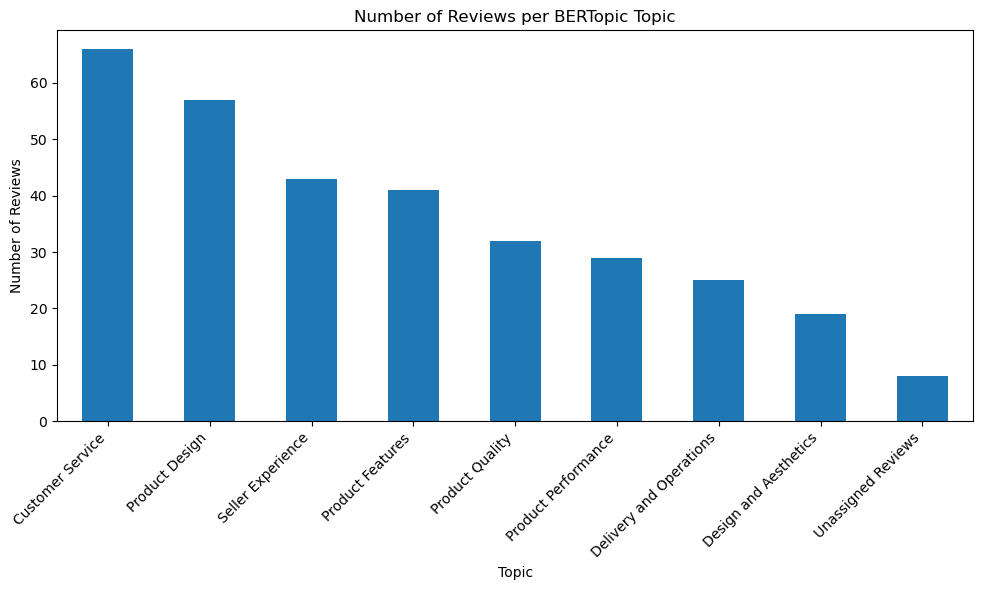

In [20]:
import matplotlib.pyplot as plt

topic_counts = (
    df["topic_name"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
topic_counts.plot(kind="bar")
plt.title("Number of Reviews per BERTopic Topic")
plt.xlabel("Topic")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. Comparison: K-Means vs BERTopic

In [29]:
print("K-Means clusters:", df["cluster"].nunique())
print("BERTopic topics excluding outliers:",
      df.loc[df["topic"] != -1, "topic"].nunique())

print("\nK-Means distribution:")
print(df["cluster"].value_counts().sort_index())

print("\nBERTopic distribution:")
print(df["topic"].value_counts().sort_index())

K-Means clusters: 5
BERTopic topics excluding outliers: 8

K-Means distribution:
cluster
0     23
1    117
2     39
3     77
4     64
Name: count, dtype: int64

BERTopic distribution:
topic
-1     8
 0    66
 1    57
 2    43
 3    41
 4    32
 5    29
 6    25
 7    19
Name: count, dtype: int64


In [30]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "reviews_with_topics.csv", index=False)
topic_model.get_topic_info().to_csv(
    output_dir / "topic_summary.csv", index=False
)

print("Results saved!")

Results saved!


## 6. Export Results

In [31]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Save reviews with their cluster and topic assignments
df.to_csv(
    output_dir / "reviews_with_topics.csv",
    index=False
)

# Save BERTopic's topic summary
topic_model.get_topic_info().to_csv(
    output_dir / "topic_summary.csv",
    index=False
)

print("Results saved successfully!")
print("Files:", list(output_dir.iterdir()))

Results saved successfully!
Files: [WindowsPath('outputs/.ipynb_checkpoints'), WindowsPath('outputs/reviews_with_topics.csv'), WindowsPath('outputs/topic_summary.csv')]
